# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [ ]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [ ]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [ ]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 509kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.7MB/s]


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [ ]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.conv(x)
        # ===== end of code ====


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.down = nn.Sequential(
            nn.AvgPool2d(kernel_size=2),
            Conv(in_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.down(x)
        # ===== end of code ====


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.up = nn.ConvTranspose2d(in_channels, in_channels, kernel_size=2, stride=2)
        self.conv = Conv(in_channels, out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.conv(self.up(x))
        # ===== end of code ====


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        super().__init__()
        self.flatten = nn.Flatten()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return x.view(x.size(0), self.in_channels, 1, 1)
        # ===== end of code ====


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        super().__init__()
        self.in_channels = in_channels
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return x.view(x.size(0), self.in_channels, 1, 1)
        # ===== end of code ====


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.block = nn.Sequential(
            Conv(in_channels, out_channels),
            Conv(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.block(x)
        # ===== end of code ====


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.down = nn.Sequential(
            DownConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.down(x)
        # ===== end of code ====


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.up = nn.Sequential(
            UpConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.up(x)
        # ===== end of code ====

## Implementing Unconditional UNet

In [ ]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.inc = ConvBlock(in_channels, num_hiddens)
        self.down1 = DownBlock(num_hiddens, num_hiddens * 2)
        self.down2 = DownBlock(num_hiddens * 2, num_hiddens * 4)
        self.mid = ConvBlock(num_hiddens * 4, num_hiddens * 4)
        self.up1 = UpBlock(num_hiddens * 4, num_hiddens * 2)
        self.up2 = UpBlock(num_hiddens * 2, num_hiddens)
        self.outc = nn.Conv2d(num_hiddens, in_channels, kernel_size=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.mid(x3)
        x5 = self.up1(x4)
        x6 = self.up2(x5)
        return self.outc(x6)
        # ===== end of code ====

# Part 1.2: Using the UNet to Train a Denoiser

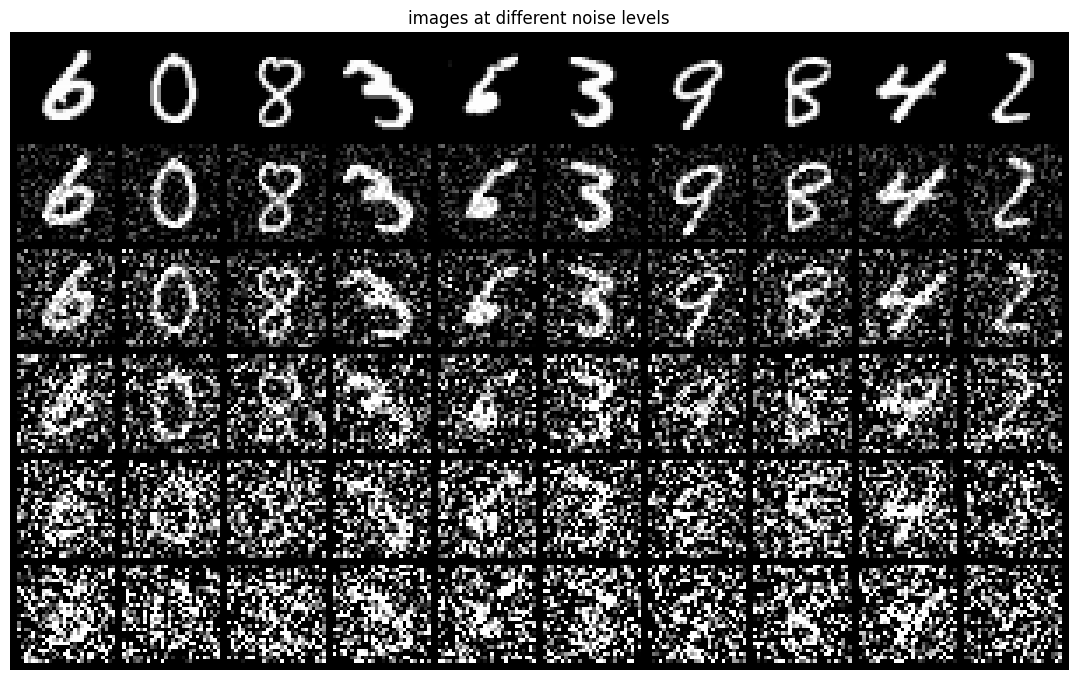

In [ ]:
# Visualize images at different noisy level
# ===== your code here! ====
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
imgs, _ = next(iter(make_loader(10)))
noisy_imgs = [torch.clamp(imgs + sigma * torch.randn_like(imgs), 0.0, 1.0) for sigma in sigmas]
show_grid(torch.vstack(noisy_imgs), "images at different noise levels", "noisy_levels.png", nrow=len(imgs))
# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [ ]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [ ]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = make_loader(batch_size, seed=SEED)

test_dataset_tensors = torch.utils.data.TensorDataset(
    test_dataset.data[:, None].float() / 255,
    test_dataset.targets
)

test_loader = DataLoader(test_dataset_tensors, batch_size=batch_size, shuffle=False)

In [ ]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

In [ ]:
# The training loops
from tqdm.auto import tqdm
train_losses = []
for epoch in range(num_epochs):
    for i, (images, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====
        images = images.to(device)
        noisy_images = images + noise_level * torch.randn_like(images)
        outputs = model(noisy_images)
        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    if epoch == 0 or epoch == num_epochs - 1:
      model.eval()
      with torch.no_grad():
        test_batch, _ = next(iter(test_loader))
        test_batch = test_batch[:10].to(device)
        noisy_test_batch = test_batch + noise_level * torch.randn_like(test_batch)
        denoised_test = model(noisy_test_batch)
        show_grid(torch.cat([noisy_test_batch, denoised_test], dim=0), f"Denoising - Epoch {epoch+1}", f"denoising_epoch_{epoch+1}.png", nrow=10)
      model.train()

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

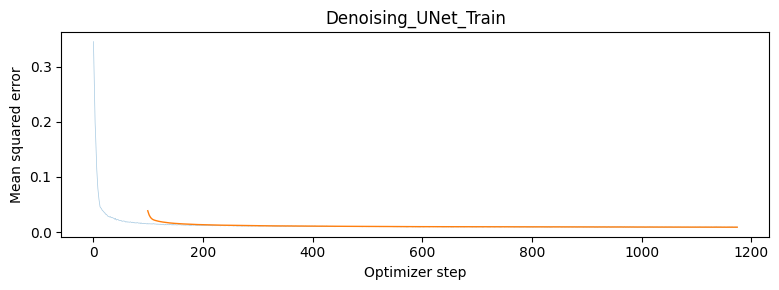

In [ ]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, "Denoising_UNet_Train")
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing



In [ ]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()
test_imgs, _ = next(iter(test_loader))
test_imgs = test_imgs.to(device)
ood_sigmas, ood_res = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0], []

with torch.no_grad():
    for sigma in ood_sigmas:
        noisy_imgs = test_imgs + sigma * torch.randn_like(test_imgs)
        ood_res.append(noisy_imgs)
        ood_res.append(model(noisy_imgs))

res_grid = torch.cat(ood_res, dim=0)
show_grid(res_grid, "OOD testing", "ood_testing.png", nrow=10)
# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

  0%|          | 0/235 [00:00<?, ?it/s]

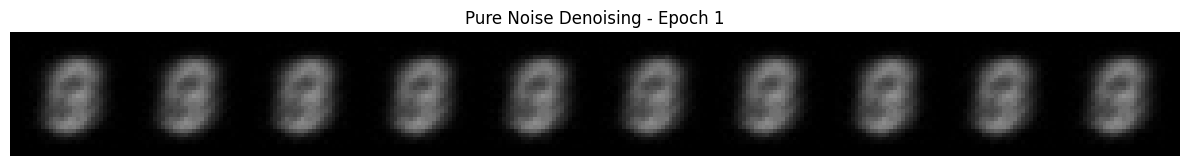

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

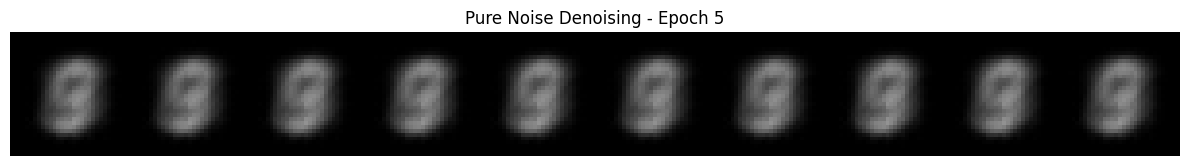

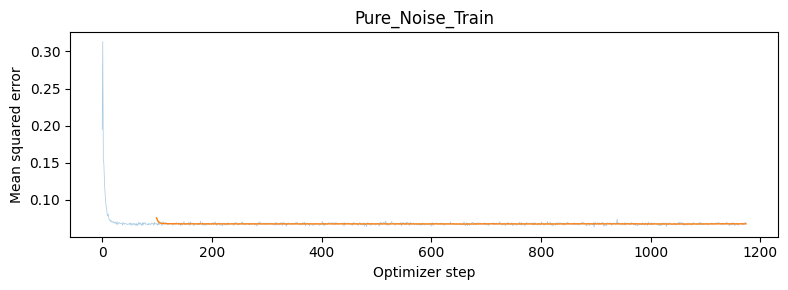

In [ ]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.
pure_noise_model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
pure_noise_optimizer = torch.optim.Adam(pure_noise_model.parameters(), lr=learning_rate)
pure_noise_train_losses = []

for epoch in range(num_epochs):
  for i, (imgs, _) in enumerate(tqdm(train_loader)):
    imgs = imgs.to(device)
    pure_noise = torch.randn_like(imgs)
    outputs = pure_noise_model(pure_noise)
    loss = criterion(outputs, imgs)
    pure_noise_optimizer.zero_grad()
    loss.backward()
    pure_noise_optimizer.step()
    pure_noise_train_losses.append(loss.item())

  if epoch == 0 or epoch == num_epochs - 1:
    pure_noise_model.eval()
    with torch.no_grad():
      sample_noise = torch.randn(10, 1, 28, 28).to(device)
      show_grid(pure_noise_model(sample_noise), f"Pure Noise Denoising - Epoch {epoch+1}", f"pure_noise_epoch_{epoch+1}.png", nrow=10)
    pure_noise_model.train()

loss_plot(pure_noise_train_losses, "Pure_Noise_Train")

Explanation: pure random Gaussian noise ($x_0$) contains no information about conditioning or any spatial signals about which digit/style was originally present. The optimal Bayes Predictor under MSE/L2 reconstruction loss is: $$\hat{x} = \mathbb{E}[x_{\text{target}} \mid x_0] = \mathbb{E}[x_{\text{target}}]$$

The network produces a fuzzy, centered, composite digit blob instead of a sharp individual number because it minimizes error by predicting the pixel-wise mean of all training digits.

# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [ ]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.block = nn.Sequential(
            nn.Linear(in_channels, out_channels),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(inplace=True)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.block(x)
        # ===== end of code ====

class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.time_embed = nn.Sequential(
            nn.Linear(1, num_hiddens),
            nn.GELU(),
            nn.Linear(num_hiddens, num_hiddens)
        )

        self.inc = ConvBlock(in_channels, num_hiddens)
        self.time_inc = FCBlock(num_hiddens, num_hiddens)
        self.down1 = DownBlock(num_hiddens, num_hiddens * 2)
        self.time_down1 = FCBlock(num_hiddens, num_hiddens * 2)
        self.down2 = DownBlock(num_hiddens * 2, num_hiddens * 4)
        self.time_down2 = FCBlock(num_hiddens, num_hiddens * 4)
        self.mid = ConvBlock(num_hiddens * 4, num_hiddens * 4)
        self.time_mid = FCBlock(num_hiddens, num_hiddens * 4)
        self.up1 = UpBlock(num_hiddens * 4, num_hiddens * 2)
        self.time_up1 = FCBlock(num_hiddens, num_hiddens * 2)
        self.up2 = UpBlock(num_hiddens * 2, num_hiddens)
        self.time_up2 = FCBlock(num_hiddens, num_hiddens)
        self.outc = nn.Conv2d(num_hiddens, in_channels, kernel_size=1)


        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t_emb = self.time_embed(t.view(-1, 1))

        x1 = self.inc(x)
        x1 = x1 + self.time_inc(t_emb).view(-1, x1.shape[1], 1, 1)
        x2 = self.down1(x1)
        x2 = x2 + self.time_down1(t_emb).view(-1, x2.shape[1], 1, 1)
        x3 = self.down2(x2)
        x3 = x3 + self.time_down2(t_emb).view(-1, x3.shape[1], 1, 1)
        x4 = self.mid(x3)
        x4 = x4 + self.time_mid(t_emb).view(-1, x4.shape[1], 1, 1)
        x5 = self.up1(x4)
        x5 = x5 + self.time_up1(t_emb).view(-1, x5.shape[1], 1, 1)
        x6 = self.up2(x5)
        x6 = x6 + self.time_up2(t_emb).view(-1, x6.shape[1], 1, 1)
        return self.outc(x6)
        # ===== end of code ====

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [ ]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    N, x_0 = x_1.shape[0], torch.randn_like(x_1)

    t = torch.rand((N,), device=x_1.device)
    t_exp = t.view(N, 1, 1, 1)

    x_t = t_exp * x_1 + (1 - t_exp) * x_0
    target_v = x_1 - x_0
    pred_v = unet(x_t, t)

    return F.mse_loss(pred_v, target_v)
    # ===== end of code ====

In [ ]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    torch.manual_seed(seed)
    N = 10
    x_t = torch.randn((N, 1, img_wh[0], img_wh[1]), device = next(unet.parameters()).device)
    dt = 1.0 / num_ts

    for i in range(num_ts):
      t = torch.full((N,), i / num_ts, device = x_t.device)
      pred_v = unet(x_t, t)
      x_t = x_t + dt * pred_v

    return x_t
    # ===== end of code ====

In [ ]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

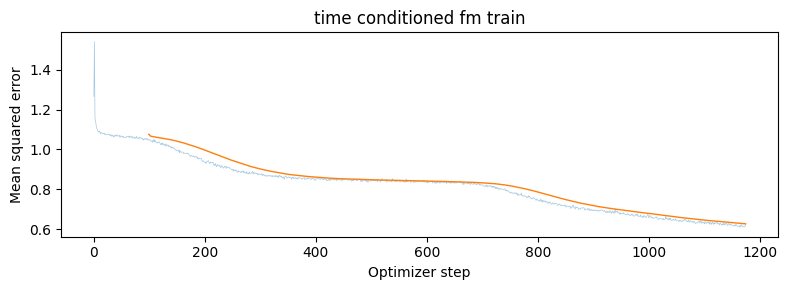

In [ ]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====
batch_size = 256
learning_rate = 1e-2
hidden_dim = 128
num_epochs = 10
time_checkpoints = {}
losses = []
num_ts = 50

model = TimeConditionalFM(
    unet=TimeConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim),
    num_ts=num_ts
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.1**(1/10))


for epoch in range(num_epochs):
    for i, (imgs, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====
        imgs = imgs.to(device)
        loss = model(imgs)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
    scheduler.step()

    if (epoch + 1) in [1, 5, 10]:
      time_checkpoints[epoch + 1] = {k: v.cpu().clone for k, v in model.state_dict().items()}

loss_plot(losses, "time conditioned fm train")
# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

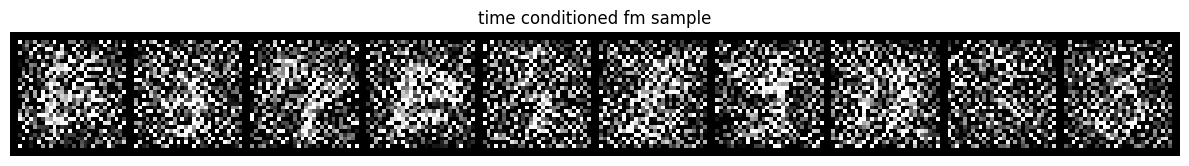

In [ ]:
# Sampling from the UNet
# ===== your code here! ====
sampled_imgs = model.sample(img_wh=(28, 28), seed=SEED)
for epoch in [1, 5, 10]:
  model.load_state_dict(time_checkpoints[epoch])
  sampled_imgs = model.sample(img_wh=(28, 28), seed=SEED)
  show_grid(sampled_imgs, "time conditioned fm sample epoch {epoch}", "time_conditioned_fm_sample_epoch_{epoch}.png", nrow=10)
# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [ ]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.time_embed = nn.Sequential(
            nn.Linear(1, num_hiddens),
            nn.GELU(),
            nn.Linear(num_hiddens, num_hiddens)
        )

        # We add 1 to accommodate the unconditioned token (class 10)
        self.class_embed = nn.Embedding(num_classes + 1, num_hiddens)

        # The concatenated conditioning embedding size is 2 * num_hiddens
        cond_dim = 2 * num_hiddens

        self.inc = ConvBlock(in_channels, num_hiddens)
        self.cond_inc = FCBlock(cond_dim, num_hiddens)
        self.down1 = DownBlock(num_hiddens, num_hiddens * 2)
        self.cond_down1 = FCBlock(cond_dim, num_hiddens * 2)
        self.down2 = DownBlock(num_hiddens * 2, num_hiddens * 4)
        self.cond_down2 = FCBlock(cond_dim, num_hiddens * 4)
        self.mid = ConvBlock(num_hiddens * 4, num_hiddens * 4)
        self.cond_mid = FCBlock(cond_dim, num_hiddens * 4)
        self.up1 = UpBlock(num_hiddens * 4, num_hiddens * 2)
        self.cond_up1 = FCBlock(cond_dim, num_hiddens * 2)
        self.up2 = UpBlock(num_hiddens * 2, num_hiddens)
        self.cond_up2 = FCBlock(cond_dim, num_hiddens)
        self.outc = nn.Conv2d(num_hiddens, in_channels, kernel_size=1)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t_emb = self.time_embed(t.view(-1, 1))
        c_emb = self.class_embed(c)
        cond_emb = torch.cat([t_emb, c_emb], dim=1)

        x1 = self.inc(x)
        x1 = x1 + self.cond_inc(cond_emb).view(-1, x1.shape[1], 1, 1)
        x2 = self.down1(x1)
        x2 = x2 + self.cond_down1(cond_emb).view(-1, x2.shape[1], 1, 1)
        x3 = self.down2(x2)
        x3 = x3 + self.cond_down2(cond_emb).view(-1, x3.shape[1], 1, 1)
        x4 = self.mid(x3)
        x4 = x4 + self.cond_mid(cond_emb).view(-1, x4.shape[1], 1, 1)
        x5 = self.up1(x4)
        x5 = x5 + self.cond_up1(cond_emb).view(-1, x5.shape[1], 1, 1)
        x6 = self.up2(x5)
        x6 = x6 + self.cond_up2(cond_emb).view(-1, x6.shape[1], 1, 1)
        return self.outc(x6)
        # ===== end of code ====

In [ ]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    N, x_0 = x_1.shape[0], torch.randn_like(x_1)

    t = torch.rand((N,), device=x_1.device)
    t_exp = t.view(N, 1, 1, 1)

    x_t = t_exp * x_1 + (1 - t_exp) * x_0
    target_v = x_1 - x_0

    mask = torch.rand(N, device=c.device) < p_uncond
    c_dropout = c.clone()
    c_dropout[mask] = 10

    prev_v = unet(x_t, c_dropout, t)
    return F.mse_loss(prev_v, target_v)
    # ===== end of code ====

In [ ]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    torch.manual_seed(seed)
    N = c.shape[0]
    x_t = torch.randn((N, 1, img_wh[0], img_wh[1]), device = next(unet.parameters()).device)
    dt = 1.0 / num_ts

    c_uncond = torch.full_like(c, 10)

    for i in range(num_ts):
      t = torch.full((N,), i / num_ts, device = x_t.device)
      v_uncond = unet(x_t, c_uncond, t)
      v_cond = unet(x_t, c, t)
      pred_v = v_uncond + guidance_scale * (v_cond - v_uncond)
      x_t += pred_v * dt

    return x_t
    # ===== end of code ====

In [ ]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

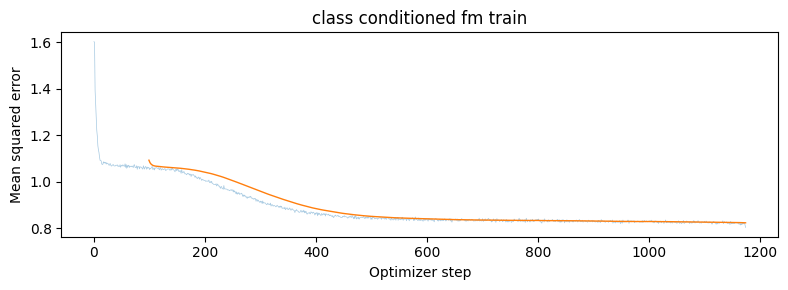

In [ ]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.
batch_size = 256
learning_rate = 1e-2
hidden_dim = 128
num_epochs = 10
num_ts = 50
checkpoint_epochs = [1, 5, 10]

class_model = ClassConditionalFM(
    unet=ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim),
    num_ts=num_ts
).to(device)

optimizer = torch.optim.Adam(class_model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.1**(1/10))
class_fm_losses = []
checkpoints = {}

for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(tqdm(train_loader)):
        images, labels = images.to(device), labels.to(device)
        loss = class_model(images, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        class_fm_losses.append(loss.item())
    scheduler.step()

    if (epoch + 1) in [1, 5, 10]:
      checkpoints[epoch + 1] = class_model.state_dict().copy()
loss_plot(class_fm_losses, "class conditioned fm train with scheduler")

lr_no_scheduler = 1e-3
class_model_no_sched = ClassConditionalFM(
    unet=ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim),
    num_ts=num_ts
).to(device)

optimizer_no_sched = torch.optim.Adam(class_model_no_sched.parameters(), lr=lr_no_scheduler)
class_fm_losses_no_sched = []

for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(tqdm(train_loader)):
        images, labels = images.to(device), labels.to(device)
        loss = class_model_no_sched(images, labels)
        optimizer_no_sched.zero_grad()
        loss.backward()
        optimizer_no_sched.step()
        class_fm_losses_no_sched.append(loss.item())

loss_plot(class_fm_losses_no_sched, "class conditioned fm train, no scheduler")

# Part 2.6: Sampling from the Class-conditioned UNet

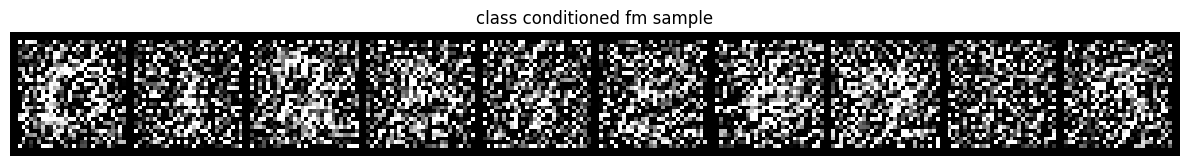

In [ ]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.
c_sample = torch.arange(10, device=device).repeat(4)
w_guidance = 5.0

for epoch in [1, 5, 10]:
  class_model.load_state_dict(checkpoints[epoch])
  sampled_digits = class_model.sample(
      c=c_sample,
      guidance_scale=w_guidance,
      img_wh=(28, 28),
      seed=SEED
  )
  show_grid(sampled_digits, f"class conditioned fm sample at epoch {epoch}", f"class_conditioned_fm_sample_epoch_{epoch}.png", nrow=10)

sampled_digits = class_model_no_sched.sample(
    c=c_sample,
    guidance_scale=w_guidance,
    img_wh=(28, 28),
    seed=SEED
)

show_grid(sampled_digits, "class conditioned fm sample, no scheduler (epoch 10)", "class_conditioned_fm_sample.png", nrow=10)

Provide a description of what you did to compensate for the loss of the scheduler.

The constant learning rate was lowered from ```1e-2``` to ```1e-3```, as it avoids divergence and gradient instability in later epochs without exponential decay factor.
Early training without the scheduler means the training ramps up more gradually vs an inital aggressive step of ```1e-2```, meaning there is a higher loss value during the first few epochs. The step doesn't vanish under a constant ```1e-3``` at the cost of minor oscillation.